# MNIST FFN: CUDA and mixed-device training

This companion to `ffn_mnist_demo.ipynb` trains the same feed-forward network on CUDA. Model parameters, intermediate tensors, gradients, and SGD state stay on the GPU during each training step. MNIST batches are loaded on the CPU and copied to the GPU; scalar losses and predictions are copied back for reporting.

The final section also tries mixed-device training: the first layer runs on the CPU and the remaining layers run on the GPU, with an explicit transfer between them. These educational kernels are not optimized, so training may be slow.

## Imports

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset
from numba import cuda

from autograd_engine.engine import Tensor, cross_entropy_loss, relu
from autograd_engine.modules import FFN
from autograd_engine.optimizers import SGD
from autograd_engine.utils import Dataset, DataLoader

if not cuda.is_available():
    raise RuntimeError("This demo requires a CUDA-capable GPU and a working CUDA setup.")

## Configuration

In [2]:
DATA_REPO = "ylecun/mnist"
LR = 0.0001
MOMENTUM = 0.9
EPOCHS = 5
BATCH_SIZE = 32
MIXED_STEPS = 10  # Short mixed-device experiment after the main run.
np.random.seed(42)

## Data

In [3]:
class MNISTDataset(Dataset):
    def __init__(self, data):
        self.data = data

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]
        image = np.asarray(item["image"], dtype=np.float32).flatten() / 255.0
        label = np.array([item["label"]], dtype=np.int64)
        return Tensor(image), Tensor(label)

In [4]:
data = load_dataset(DATA_REPO)
train_data = MNISTDataset(data["train"])
test_data = MNISTDataset(data["test"])
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)
print(f"Training examples: {len(train_data):,}; test examples: {len(test_data):,}")

Training examples: 60,000; test examples: 10,000


## CUDA training

In [5]:
model = FFN(in_features=28 * 28, hidden_features=128, out_features=10).to("cuda")
optimizer = SGD(model.parameters, lr=LR, momentum=MOMENTUM)
loss_values = []

for epoch in range(EPOCHS):
    total_loss = 0.0
    for batch_idx, (images, labels) in enumerate(train_loader):
        images = images.cuda()
        labels = labels.cuda()
        optimizer.zero_grad()
        loss = cross_entropy_loss(model(images), labels)
        loss.backward()
        optimizer.step()

        # Copy only the scalar to the CPU for reporting.
        loss_value = loss.cpu().data.item()
        total_loss += loss_value
        loss_values.append(loss_value)
        if (batch_idx + 1) % 100 == 0:
            print(f"Epoch [{epoch + 1}/{EPOCHS}], Step {batch_idx + 1}, "
                  f"Loss: {total_loss / (batch_idx + 1):.4f}")
    print(f"Epoch [{epoch + 1}/{EPOCHS}] completed.")

Epoch [1/5], Step 100, Loss: 2.3368
Epoch [1/5], Step 200, Loss: 2.2799
Epoch [1/5], Step 300, Loss: 2.2344
Epoch [1/5], Step 400, Loss: 2.1919
Epoch [1/5], Step 500, Loss: 2.1499
Epoch [1/5], Step 600, Loss: 2.1114
Epoch [1/5], Step 700, Loss: 2.0773
Epoch [1/5], Step 800, Loss: 2.0416
Epoch [1/5], Step 900, Loss: 2.0065
Epoch [1/5], Step 1000, Loss: 1.9699
Epoch [1/5], Step 1100, Loss: 1.9346
Epoch [1/5], Step 1200, Loss: 1.9009
Epoch [1/5], Step 1300, Loss: 1.8675
Epoch [1/5], Step 1400, Loss: 1.8320
Epoch [1/5], Step 1500, Loss: 1.7997
Epoch [1/5], Step 1600, Loss: 1.7682
Epoch [1/5], Step 1700, Loss: 1.7368
Epoch [1/5], Step 1800, Loss: 1.7062
Epoch [1/5] completed.
Epoch [2/5], Step 100, Loss: 1.1098
Epoch [2/5], Step 200, Loss: 1.1017
Epoch [2/5], Step 300, Loss: 1.0811
Epoch [2/5], Step 400, Loss: 1.0626
Epoch [2/5], Step 500, Loss: 1.0422
Epoch [2/5], Step 600, Loss: 1.0278
Epoch [2/5], Step 700, Loss: 1.0123
Epoch [2/5], Step 800, Loss: 0.9992
Epoch [2/5], Step 900, Loss: 0.9

## Evaluation

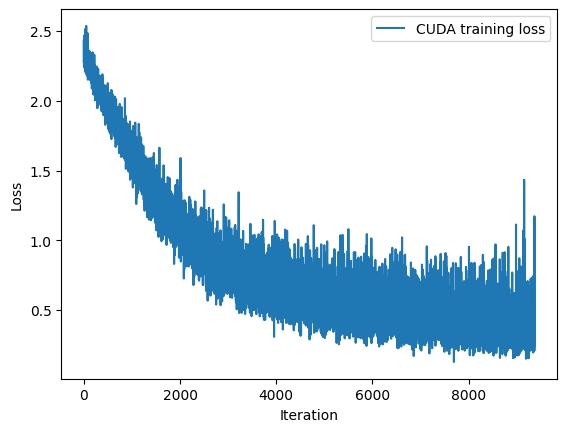

In [6]:
plt.plot(loss_values, label="CUDA training loss")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [7]:
correct = 0
total = 0
correct_examples = []
incorrect_examples = []

for images, labels in test_loader:
    predictions = np.argmax(model(images.cuda()).cpu().data, axis=1)
    target = labels.data.flatten()
    correct += int((predictions == target).sum())
    total += len(target)
    for image, label, prediction in zip(images.data, target, predictions):
        examples = correct_examples if label == prediction else incorrect_examples
        if len(examples) < 5:
            examples.append((image.reshape(28, 28), int(label), int(prediction)))

print(f"Test accuracy: {100 * correct / total:.2f}%")

Test accuracy: 88.54%


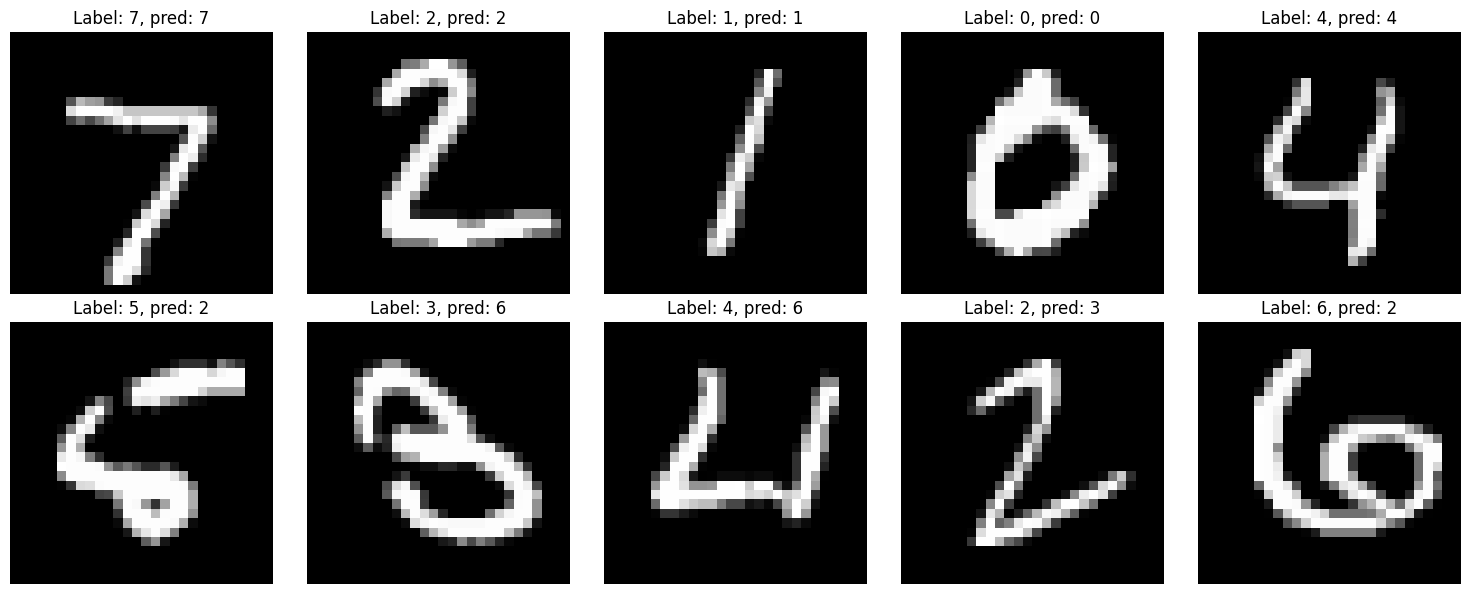

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for row, examples in enumerate((correct_examples, incorrect_examples)):
    for col, ax in enumerate(axes[row]):
        ax.axis("off")
        if col < len(examples):
            image, label, prediction = examples[col]
            ax.imshow(image, cmap="gray")
            ax.set_title(f"Label: {label}, pred: {prediction}")
plt.tight_layout()
plt.show()

## Mixed-device training experiment

This creates a separate model: layer 1 stays on CPU, while layers 2 and 3 are on CUDA. The activation and its gradient cross the device boundary explicitly. It is a demonstration of device placement, not a performance optimization.

In [ ]:
mixed_model = FFN(in_features=28 * 28, hidden_features=128, out_features=10)
mixed_model.linear2.to("cuda")
mixed_model.linear3.to("cuda")
mixed_optimizer = SGD(mixed_model.parameters, lr=LR, momentum=MOMENTUM)
mixed_losses = []

for batch_idx, (images, labels) in enumerate(train_loader):
    if batch_idx >= MIXED_STEPS:
        break
    mixed_optimizer.zero_grad()
    # The first layer runs on the CPU; .cuda() records the transfer for backprop.
    hidden = relu(mixed_model.linear1(images)).cuda()
    hidden = relu(mixed_model.linear2(hidden))
    outputs = mixed_model.linear3(hidden)
    loss = cross_entropy_loss(outputs, labels.cuda())
    loss.backward()
    mixed_optimizer.step()
    mixed_losses.append(loss.cpu().data.item())
    print(f"Mixed step {batch_idx + 1}: loss={mixed_losses[-1]:.4f}")

print("Layer devices:", mixed_model.linear1.W.device,
      mixed_model.linear2.W.device, mixed_model.linear3.W.device)